In [1]:

from tensorflow.keras.optimizers import SGD,Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D,Input,concatenate,add
from keras.callbacks import ModelCheckpoint, TensorBoard, EarlyStopping, CSVLogger
from keras.models import Sequential, Model
from tensorflow.keras.layers import Dense, Dropout, Flatten, Activation, BatchNormalization,SeparableConv2D,Reshape,Permute,multiply
from tensorflow.keras.layers import Conv2D, MaxPooling2D,AveragePooling2D
import time
import os.path
import itertools
#import cv2
from glob import glob
import matplotlib.pyplot as plt
from tensorflow.keras.utils import plot_model
from tensorflow.keras.optimizers import SGD ,RMSprop
from tensorflow.keras.callbacks import LearningRateScheduler,ReduceLROnPlateau
import math
import keras
from tensorflow.keras.regularizers import l2
import os
import keras.backend as K
import tensorflow as tf
from sklearn.utils import class_weight
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize
import seaborn as sns
# os.environ["PATH"] += os.pathsep + 'C:/Program Files/Graphviz/bin/'

2025-04-28 16:02:56.699067: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1745856177.017114      31 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1745856177.098252      31 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [2]:

train_data_dir = '/kaggle/input/osteosarcoma/dataset/train'
valid_data_dir = '/kaggle/input/osteosarcoma/dataset/validate'
test_data_dir  = '/kaggle/input/osteosarcoma/dataset/test'

batch_size=16
checkpointer = ModelCheckpoint(
    filepath=os.path.join('Data', 'checkpoints', 'model_Dataset_Grade_2.keras'),
    verbose=1,
    save_best_only=True)


early_stopper = EarlyStopping(monitor='val_loss', patience=20)


tensorboard = TensorBoard(log_dir=os.path.join('Data', 'logs'))
timestamp = time.time()
csv_logger = CSVLogger(os.path.join('Data', 'logs', 'model_Dataset_Grade_2' + '-' + 'training-' + \
        str(timestamp) + '.log'))

In [3]:
def get_generators():

    train_datagen = ImageDataGenerator(
        rescale=1./255,
                zoom_range=0.05,
                #brightness_range=(0.9, 1.1),
                #histogram_equalization=True,
                rotation_range=20,
                shear_range=0.05,
                width_shift_range=0.1,
                height_shift_range=0.1,
                horizontal_flip=True,
                vertical_flip=True,
                fill_mode='nearest',
                #featurewise_center=True
                )


    val_datagen = ImageDataGenerator(rescale=1./255)



    train_generator = train_datagen.flow_from_directory(
        train_data_dir,
        target_size=(1024, 1024),
        batch_size=batch_size,
        shuffle=True,
        color_mode="rgb",
        classes=['Non-Tumor', 'Non-Viable-Tumor', 'Viable'],
        class_mode='categorical')

    validation_generator = val_datagen.flow_from_directory(
        valid_data_dir,
        target_size=(1024, 1024),
        batch_size=batch_size,
        color_mode="rgb",
        shuffle=False,
        classes=['Non-Tumor', 'Non-Viable-Tumor', 'Viable'],
        class_mode='categorical')

    
    test_generator = val_datagen.flow_from_directory(
        test_data_dir,
        target_size=(1024, 1024),
        batch_size=batch_size,
        color_mode="rgb",
        shuffle=False,
        classes=['Non-Tumor', 'Non-Viable-Tumor', 'Viable'],
        class_mode='categorical'
    )


    return train_generator, validation_generator, test_generator

In [4]:
train_generator, validation_generator, test_generator = get_generators()

Found 640 images belonging to 3 classes.
Found 231 images belonging to 3 classes.
Found 177 images belonging to 3 classes.


In [5]:
print(len(validation_generator.filenames))

231


In [6]:
kernel_init = keras.initializers.glorot_uniform()
bias_init = keras.initializers.Constant(value=0.2)

def _tensor_shape(tensor):
    return getattr(tensor, '_shape_val') if TF else getattr(tensor, '_keras_shape')

In [7]:
def CAM(input_tensor):

    init = input_tensor
    print(init.shape)
    channel_axis = 1 if K.image_data_format() == "channels_first" else -1
    filters =init.shape[channel_axis]
    se_shape = (1, 1, filters)

    se = GlobalAveragePooling2D()(init)
    se = Reshape(se_shape)(se)
    se = SeparableConv2D(filters, (1, 1), padding='same', activation='relu', depthwise_initializer=kernel_init,
   pointwise_initializer=kernel_init, bias_initializer=bias_init)(se)
    se=BatchNormalization()(se)
    se = SeparableConv2D(filters, (1, 1), padding='same', activation='relu', depthwise_initializer=kernel_init,
   pointwise_initializer=kernel_init, bias_initializer=bias_init)(se)

    if K.image_data_format() == 'channels_first':
        se = Permute((3, 1, 2))(se)

    x = add([init, se])
    return x

In [8]:
def grouped_convolutions(x,
                     filters_1,
                     filters_2,
                     filters_3,
                     filters_4,
                     filters_5):

    conv_1 = SeparableConv2D(filters_1, (1, 1), padding='same', activation='relu', depthwise_initializer=kernel_init,
   pointwise_initializer=kernel_init, bias_initializer=bias_init)(x)

    conv_1_b = BatchNormalization()(conv_1)



    conv_2 = SeparableConv2D(filters_2, (3, 3), padding='same', activation='relu', depthwise_initializer=kernel_init,
   pointwise_initializer=kernel_init, bias_initializer=bias_init)(x)
    conv_2_b = BatchNormalization()(conv_2)



    conv_3= SeparableConv2D(filters_3, (5, 5), padding='same', activation='relu', depthwise_initializer=kernel_init,
   pointwise_initializer=kernel_init, bias_initializer=bias_init)(x)
    conv_3_b = BatchNormalization()(conv_3)

    conv_4= SeparableConv2D(filters_4, (7, 7), padding='same', activation='relu', depthwise_initializer=kernel_init,
   pointwise_initializer=kernel_init, bias_initializer=bias_init)(x)
    conv_4_b = BatchNormalization()(conv_4)

    conv_5 = SeparableConv2D(filters_5, (9, 9), padding='same', activation='relu', depthwise_initializer=kernel_init,
   pointwise_initializer=kernel_init, bias_initializer=bias_init)(x)
    conv_5_b = BatchNormalization()(conv_5)




    output = add([conv_1_b, conv_2_b, conv_3_b, conv_4_b, conv_5_b])
    print(output.shape[-1])

    return output

In [9]:
def Breast_NET_block(x, filters_1x1, filters_3x3, filters_5x5, filters_7x7, filters_9x9):

    x_0 = grouped_convolutions(x,
                         filters_1x1,
                         filters_3x3,
                         filters_5x5,
                         filters_7x7,
                         filters_9x9)


    x_2 = keras.layers.Activation("relu")(x_0)


    x_=CAM(x_2)

    return keras.layers.Activation("relu")(x_)

In [10]:

def srima():
    input_layer = Input(shape=(1024, 1024, 3))

    x = SeparableConv2D(64, (3, 3), padding='same', strides=(2, 2), activation='relu', depthwise_initializer=kernel_init,
   pointwise_initializer=kernel_init, bias_initializer=bias_init, name='conv_1')(input_layer)
    x = BatchNormalization()(x)
    x = MaxPooling2D((3, 3), padding='same',  name='max_pool_1_3x3')(x)

    x=Breast_NET_block(x,
                         filters_1x1=64,
                         filters_3x3=64,
                         filters_5x5=64,
                         filters_7x7=64,
                         filters_9x9=64)
    x=Breast_NET_block(x,
                         filters_1x1=96,
                         filters_3x3=96,
                         filters_5x5=96,
                         filters_7x7=96,
                         filters_9x9=96)
    x=Breast_NET_block(x,
                         filters_1x1=120,
                         filters_3x3=120,
                         filters_5x5=120,
                         filters_7x7=120,
                         filters_9x9=120)

    x1 = GlobalAveragePooling2D(name='avg_pool')(x)


    x1 = Dropout(0.4)(x1)
    x1 = Dense(3, activation='softmax', name='output')(x1)



    model = Model(input_layer, x1, name='Breast_NET')


    print(model.summary())
    #plot_model(model, to_file='model_BreaKHis_v10.png', show_shapes=True, show_layer_names=True)
    print("Number of layers in the base model: ", len(model.layers))

    return model

In [11]:
learning_rate_reduction = ReduceLROnPlateau(monitor='val_loss',
                                            patience=5,
                                            verbose=1,
                                            factor=0.2,
                                            min_lr=0.00001)

In [12]:
def train_model(model, nb_epoch, generators,callbacks=[]):

    train_generator, validation_generator = generators

    optimizer = Adam(learning_rate=1e-4)
    loss = tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1)
    model.compile(optimizer=optimizer, loss= loss, metrics=['accuracy'])
    model._get_distribution_strategy = lambda: None

    print("train_generator.classes:", train_generator.classes[:10])
    print("np.unique(train_generator.classes):", np.unique(train_generator.classes))
    print("type of elements:", type(train_generator.classes[0]))

    class_weights = class_weight.compute_class_weight(
                class_weight ='balanced',
                classes = np.unique(train_generator.classes),
                y = train_generator.classes)

    class_weights = dict(zip(np.unique(train_generator.classes), class_weights))

    print(class_weights)
    classWeight = dict()
    his=model.fit(
        train_generator,
        steps_per_epoch=len(train_generator.filenames) // batch_size,
        validation_data=validation_generator,
        validation_steps=len(validation_generator.filenames) // batch_size,
        epochs=nb_epoch,
        class_weight=class_weights,
        #class_weight='balanced',
        # Temporarily disable early stopping
        callbacks = callbacks
        )

    fig, axs = plt.subplots(1, 2, figsize = (15, 4))
    training_loss = his.history['loss']
    validation_loss = his.history['val_loss']
    training_accuracy = his.history['accuracy']
    validation_accuracy = his.history['val_accuracy']
    epoch_count = range(1, len(training_loss) + 1)
    
    #N=num_epochs
    axs[0].plot(epoch_count, training_loss, 'r--')
    axs[0].plot(epoch_count, validation_loss, 'b-')
    axs[0].legend(['Training Loss', 'Validation Loss'])
    axs[0].set_xlabel("Epoch")
    axs[0].set_ylabel("Loss")
    axs[1].plot(epoch_count, training_accuracy, 'r--')
    axs[1].plot(epoch_count, validation_accuracy, 'b-')
    axs[1].legend(['Training Accuracy', 'Validation Accuracy'])
    axs[1].set_xlabel("Epoch")
    axs[1].set_ylabel("Accuracy")
    fig.savefig('/kaggle/working/Data/model_Dataset_Grade_2.png')

    return model

In [13]:
def main(weights_file):


    model = srima()

    train_generator, validation_generator, test_generator = get_generators()

    
    from tensorflow.python.profiler.model_analyzer import profile
    from tensorflow.python.profiler.option_builder import ProfileOptionBuilder
    print('TensorFlow:', tf.__version__)

    
    forward_pass = tf.function(
        model.call,
        input_signature=[tf.TensorSpec(shape=(1,) + model.input_shape[1:])])

    graph_info = profile(forward_pass.get_concrete_function().graph,
                            options=ProfileOptionBuilder.float_operation())


    flops = graph_info.total_float_ops // 2
    print(f"FLOPS: {flops / 10 ** 9:.03} G")

    if weights_file is None:
        print("Loading network.")

        model = train_model(model, 300, (train_generator, validation_generator),
                        [checkpointer, tensorboard, csv_logger])

    else:
        print("Loading saved model: %s." % weights_file)
        model.load_weights(weights_file)



    # ------------- Start of Evaluation Part -------------

    print("Evaluating model on TEST set...")

    # Predict
    y_pred_probs = model.predict(test_generator, verbose=1)
    y_pred = np.argmax(y_pred_probs, axis=1)

    # True labels
    y_true = test_generator.classes

    # Confusion matrix
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8,6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True,
                xticklabels=['Non-Tumor', 'Non-Viable-Tumor', 'Viable'],
                yticklabels=['Non-Tumor', 'Non-Viable-Tumor', 'Viable'])
    plt.xlabel('Predicted Labels')
    plt.ylabel('True Labels')
    plt.title('Confusion Matrix')
    plt.savefig('/kaggle/working/Data/confusion_matrix.png')
    plt.show()
    plt.close()


    # Classification report
    target_names = list(test_generator.class_indices.keys())
    print("Classification Report:\n", classification_report(y_true, y_pred, target_names=target_names))
    report = classification_report(y_true, y_pred, target_names=target_names)
    with open('/kaggle/working/Data/classification_report.txt', 'w') as f:
        f.write(report)

    # ROC curve for each class
    y_true_bin = label_binarize(y_true, classes=[0,1,2])

    fpr = dict()
    tpr = dict()
    roc_auc = dict()
    for i in range(3):
        fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_pred_probs[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    # Plot ROC curves for each class
    plt.figure(figsize=(8,6))
    colors = ['blue', 'red', 'green']
    for i, color in zip(range(3), colors):
        plt.plot(fpr[i], tpr[i], color=color, lw=2,
                 label=f'ROC curve for class {target_names[i]} (area = {roc_auc[i]:.2f})')

    plt.plot([0, 1], [0, 1], 'k--', lw=2)
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curves for Each Class')
    plt.legend(loc="lower right")
    plt.grid()
    plt.savefig('/kaggle/working/Data/roc_curves.png')
    plt.show()
    plt.close()

    # ------------- End of Evaluation Part -------------

    import shutil

    print("Zipping output folder...")
    shutil.make_archive('/kaggle/working/output_folder', 'zip', '/kaggle/working/Data')
    print("Zip saved at /kaggle/working/output_folder.zip")


I0000 00:00:1745856193.526112      31 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13942 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1745856193.526802      31 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13942 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


64
(None, 171, 171, 64)
96
(None, 171, 171, 96)
120
(None, 171, 171, 120)


Model: "Breast_NET"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)  │ (None, 1024, 1024, 3)  │              0 │ -                      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv_1 (SeparableConv2D)  │ (None, 512, 512, 64)   │            283 │ input_layer[0][0]      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization       │ (None, 512, 512, 64)   │            256 │ conv_1[0][0]           │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ max_pool_1_3x3            │ (None, 171, 171, 64)   │              0 │ batch_normalization[0… │
│ (MaxPooling2D)            │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ separable_conv2d          │ (None, 171, 171, 64)   │          4,224 │ max_pool_1_3x3[0][0]   │
│ (SeparableConv2D)         │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ separable_conv2d_1        │ (None, 171, 171, 64)   │          4,736 │ max_pool_1_3x3[0][0]   │
│ (SeparableConv2D)         │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ separable_conv2d_2        │ (None, 171, 171, 64)   │          5,760 │ max_pool_1_3x3[0][0]   │
│ (SeparableConv2D)         │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ separable_conv2d_3        │ (None, 171, 171, 64)   │          7,296 │ max_pool_1_3x3[0][0]   │
│ (SeparableConv2D)         │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ separable_conv2d_4        │ (None, 171, 171, 64)   │          9,344 │ max_pool_1_3x3[0][0]   │
│ (SeparableConv2D)         │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_1     │ (None, 171, 171, 64)   │            256 │ separable_conv2d[0][0] │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_2     │ (None, 171, 171, 64)   │            256 │ separable_conv2d_1[0]… │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_3     │ (None, 171, 171, 64)   │            256 │ separable_conv2d_2[0]… │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_4     │ (None, 171, 171, 64)   │            256 │ separable_conv2d_3[0]… │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_5     │ (None, 171, 171, 64)   │            256 │ separable_conv2d_4[0]… │
│ (BatchNormalization) 

 Total params: 211,326 (825.49 KB)

...

40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.5514 - loss: 1.8289

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()



Epoch 1: val_loss improved from inf to 1.68310, saving model to Data/checkpoints/model_Dataset_Grade_2.keras
40/40 ━━━━━━━━━━━━━━━━━━━━ 227s 4s/step - accuracy: 0.5527 - loss: 1.8207 - val_accuracy: 0.3125 - val_loss: 1.6831
Epoch 2/300


/usr/lib/python3.11/contextlib.py:158: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self.gen.throw(typ, value, traceback)



Epoch 2: val_loss improved from 1.68310 to 0.69535, saving model to Data/checkpoints/model_Dataset_Grade_2.keras
40/40 ━━━━━━━━━━━━━━━━━━━━ 5s 127ms/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.6954
Epoch 3/300
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.6965 - loss: 1.0383
Epoch 3: val_loss did not improve from 0.69535
40/40 ━━━━━━━━━━━━━━━━━━━━ 162s 3s/step - accuracy: 0.6966 - loss: 1.0386 - val_accuracy: 0.3929 - val_loss: 1.2587
Epoch 4/300

Epoch 4: val_loss did not improve from 0.69535
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.8843
Epoch 5/300
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.7134 - loss: 0.9563
Epoch 5: val_loss did not improve from 0.69535
40/40 ━━━━━━━━━━━━━━━━━━━━ 163s 3s/step - accuracy: 0.7136 - loss: 0.9565 - val_accuracy: 0.3929 - val_loss: 1.1015
Epoch 6/300

Epoch 6: val_loss did not improve from 0.69535
40/40 ━━━━━━━━━━━━━━

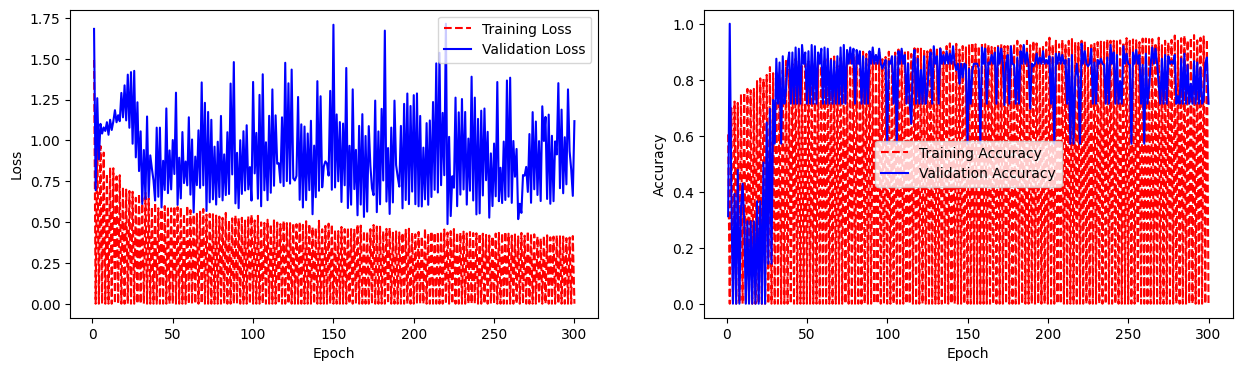

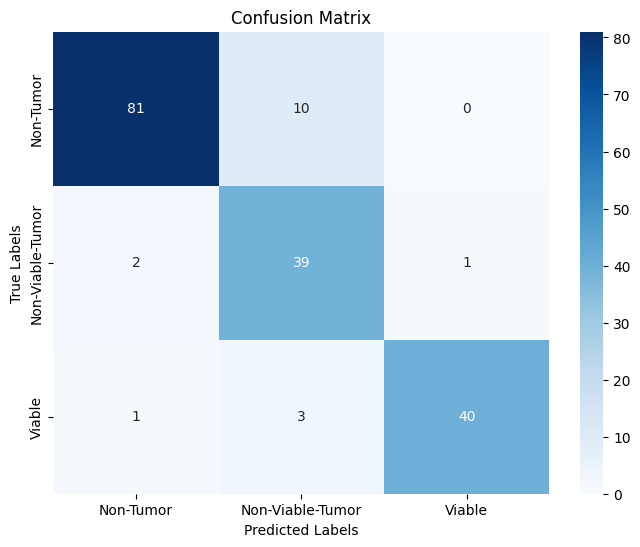

Classification Report:
                   precision    recall  f1-score   support

       Non-Tumor       0.96      0.89      0.93        91
Non-Viable-Tumor       0.75      0.93      0.83        42
          Viable       0.98      0.91      0.94        44

        accuracy                           0.90       177
       macro avg       0.90      0.91      0.90       177
    weighted avg       0.92      0.90      0.91       177



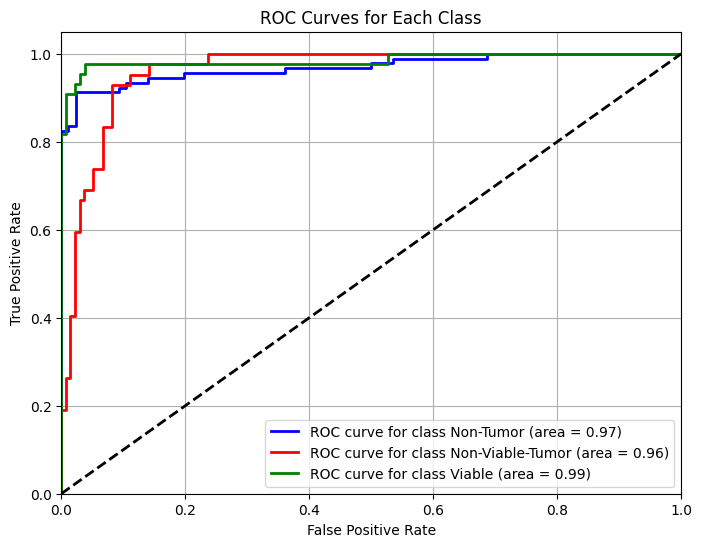

Zipping output folder...
Zip saved at /kaggle/working/output_folder.zip


In [14]:
if __name__ == '__main__':
    weights_file = None
    #print(len(data.classes))
    main(weights_file)